In [ ]:
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
main_df = pd.read_csv('/content/drive/MyDrive/Datasets/PlayStoreReviewsMultipleCategoires.csv') # combined_apps_reviews # gen_ai_reviews_main_dataset #gen_ai_reviews_5_apps_dataset #PlayStoreReviewsMultipleCategoires

main_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500135 entries, 0 to 500134
Data columns (total 9 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   app_id                500135 non-null  object 
 1   app_name              500135 non-null  object 
 2   app_category          500135 non-null  object 
 3   app_aggregate_rating  500135 non-null  float64
 4   review_text           500117 non-null  object 
 5   review_rating         500135 non-null  int64  
 6   helpful_votes         500135 non-null  int64  
 7   review_date           500135 non-null  object 
 8   scraped_at            500135 non-null  object 
dtypes: float64(1), int64(2), object(6)
memory usage: 34.3+ MB


In [ ]:
sample_percentage = 1 # Set the desired sample percentage (e.g., 0.50 for 50%, 1 for 100%)
df = main_df.sample(frac=sample_percentage, random_state=42) # random_state for reproducibility

print(f"New DataFrame size: {len(df)} records ({sample_percentage*100}% of original)")


New DataFrame size: 500135 records (100% of original)


### **Preprocessing (In Manuscript Section 4.1)**

In [ ]:
df = df[df['review_rating'].isin([1, 2, 3, 4, 5])]

In [ ]:
len(df)

500135

In [ ]:
df["review_rating_original"] = df["review_rating"].copy()

### **Phase 1: Quantile based Sentiment Label Generation (In Manuscript Section 4.2.1)**
The code below creates an initial rough labeling of reviews into 5 rating classes purely from how positive or negative the text sounds, using sentiment score cutoffs rather than the actual star ratings, then checks whether that labeling makes sense by confirming sentiment increases steadily from the lowest to highest class and by measuring how much vocabulary overlaps between neighboring classes, which together tell you whether this seed labeling is a good enough starting point before the cascade process refines it further.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from nltk.sentiment.vader import SentimentIntensityAnalyzer

import nltk
nltk.download('vader_lexicon')

sia = SentimentIntensityAnalyzer()

# baseline: original star ratings
df_baseline = df.copy()
df_baseline['review_text'] = df_baseline['review_text'].fillna('').astype(str).str.strip()
df_baseline['sentiment'] = df_baseline['review_text'].apply(lambda t: sia.polarity_scores(t)['compound'])

# cascade: sentiment-quantile seeding
df_cascade = df.copy()
df_cascade['review_text'] = df_cascade['review_text'].fillna('').astype(str).str.strip()
df_cascade['sentiment'] = df_cascade['review_text'].apply(lambda t: sia.polarity_scores(t)['compound'])

quantile_bounds = df_cascade['sentiment'].quantile([0.2, 0.4, 0.6, 0.8]).values
t1, t2, t3, t4 = quantile_bounds

def seed_class(score):
    if score < t1:
        return 1
    if score < t2:
        return 2
    if score < t3:
        return 3
    if score < t4:
        return 4
    return 5

df_cascade['review_rating'] = df_cascade['sentiment'].apply(seed_class)

count_vec = CountVectorizer(max_features=20000, min_df=2, ngram_range=(1, 2))
count_vec.fit(df_cascade['review_text'])

active_classes = [1, 2, 3, 4, 5]
adjacent_pairs = [(1, 2), (2, 3), (3, 4), (4, 5)]
ambiguity_margin = 0.05

def get_centroid(texts):
    vecs = count_vec.transform(texts)
    return np.asarray(vecs.mean(axis=0))

def print_distribution(df_in, tag):
    print(f'-- {tag} --------------------------------------------------')
    print(df_in['review_rating'].value_counts().sort_index())
    print()

def evaluate_labeling(df_in, active_classes, tag):
    print(f'-- {tag} --------------------------------------------------')
    means = {}
    overlaps = {}
    for cls in active_classes:
        scores = df_in[df_in['review_rating'] == cls]['sentiment']
        means[cls] = scores.mean()
        print(f'  cls{cls}: sentiment mean {scores.mean():+.3f}  |  n {len(scores)}')

    pairs = [(active_classes[i], active_classes[i+1]) for i in range(len(active_classes)-1)]
    print('  sentiment gaps (adjacent):', end='  ')
    for c1, c2 in pairs:
        print(f'cls{c1}->cls{c2}: {abs(means[c1]-means[c2]):.3f}', end='  ')
    monotonic = all(means[pairs[i][0]] < means[pairs[i][1]] for i in range(len(pairs)))
    print(f'\n  sentiment ordering: {"monotonic, valid" if monotonic else "not monotonic, invalid"}')

    vocabs = {}
    for cls in active_classes:
        cls_content = df_in[df_in['review_rating'] == cls]['review_text'].fillna('').astype(str)
        vocabs[cls] = set(count_vec.build_analyzer()(' '.join(cls_content)))
    print('  vocab jaccard overlap (adjacent):', end='  ')
    for c1, c2 in pairs:
        shared = len(vocabs[c1] & vocabs[c2])
        union = len(vocabs[c1] | vocabs[c2])
        overlap = shared / union * 100 if union else 0
        overlaps[(c1, c2)] = overlap
        print(f'cls{c1}vs{c2}: {overlap:.1f}%', end='  ')
    print('\n')
    return means, overlaps, monotonic

# baseline
print_distribution(df_baseline, 'phase 0, original star ratings (baseline)')
base_means, base_overlaps, base_mono = evaluate_labeling(df_baseline, active_classes, 'phase 0, original star ratings (baseline)')

# cascade
print_distribution(df_cascade, 'phase 1, after sentiment-quantile seeding')
casc_means, casc_overlaps, casc_mono = evaluate_labeling(df_cascade, active_classes, 'phase 1, after sentiment-quantile seeding')

# difference
print('== difference (phase 1 minus baseline) ==============================')
pairs = adjacent_pairs

print('  raw label gaps (adjacent):    ', '  '.join(f'cls{c1}->cls{c2}: {abs(base_means[c1]-base_means[c2]):.3f}' for c1, c2 in pairs))
print('  new label gaps (adjacent):    ', '  '.join(f'cls{c1}->cls{c2}: {abs(casc_means[c1]-casc_means[c2]):.3f}' for c1, c2 in pairs))

print('  sentiment mean shift per class:')
for cls in active_classes:
    print(f'    cls{cls}: {base_means[cls]:+.3f} -> {casc_means[cls]:+.3f}  (delta {casc_means[cls]-base_means[cls]:+.3f})')

print('  adjacent sentiment gap change:')
for c1, c2 in pairs:
    base_gap = abs(base_means[c1] - base_means[c2])
    casc_gap = abs(casc_means[c1] - casc_means[c2])
    print(f'    cls{c1}->cls{c2}: {base_gap:.3f} -> {casc_gap:.3f}  (delta {casc_gap-base_gap:+.3f})')

print('  adjacent vocab overlap change:')
for c1, c2 in pairs:
    print(f'    cls{c1}vs{c2}: {base_overlaps[(c1,c2)]:.1f}% -> {casc_overlaps[(c1,c2)]:.1f}%  (delta {casc_overlaps[(c1,c2)]-base_overlaps[(c1,c2)]:+.1f}%)')

base_mean_gap = np.mean([abs(base_means[c1]-base_means[c2]) for c1, c2 in pairs])
casc_mean_gap = np.mean([abs(casc_means[c1]-casc_means[c2]) for c1, c2 in pairs])
base_mean_ov = np.mean([base_overlaps[(c1,c2)] for c1, c2 in pairs])
casc_mean_ov = np.mean([casc_overlaps[(c1,c2)] for c1, c2 in pairs])

print('  summary:')
print(f'    avg adjacent gap:     {base_mean_gap:.3f} -> {casc_mean_gap:.3f}  (delta {casc_mean_gap-base_mean_gap:+.3f})')
print(f'    avg adjacent overlap: {base_mean_ov:.1f}% -> {casc_mean_ov:.1f}%  (delta {casc_mean_ov-base_mean_ov:+.1f}%)')
print(f'    ordering: baseline {"monotonic" if base_mono else "not monotonic"} -> phase 1 {"monotonic" if casc_mono else "not monotonic"}')

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


-- phase 0, original star ratings (baseline) --------------------------------------------------
review_rating
1    117997
2     29006
3     31407
4     48336
5    273389
Name: count, dtype: int64

-- phase 0, original star ratings (baseline) --------------------------------------------------
  cls1: sentiment mean -0.117  |  n 117997
  cls2: sentiment mean +0.012  |  n 29006
  cls3: sentiment mean +0.178  |  n 31407
  cls4: sentiment mean +0.424  |  n 48336
  cls5: sentiment mean +0.517  |  n 273389
  sentiment gaps (adjacent):  cls1->cls2: 0.129  cls2->cls3: 0.166  cls3->cls4: 0.246  cls4->cls5: 0.093  
  sentiment ordering: monotonic, valid
  vocab jaccard overlap (adjacent):  cls1vs2: 19.0%  cls2vs3: 22.5%  cls3vs4: 21.7%  cls4vs5: 17.8%  

-- phase 1, after sentiment-quantile seeding --------------------------------------------------
review_rating
1     91860
2    108040
3     99624
4    100016
5    100595
Name: count, dtype: int64

-- phase 1, after sentiment-quantile seeding ----

### **Phase 2: TF-IDF Vocabulary Based Cascade Refinement (In Manuscript Section 4.2.2)**
The code below finds the best value for "ambiguity_margin". It samples a subset, refits a smaller TF-IDF on that subset, and runs each candidate margin through a few passes only. It ranks candidates by average adjacent vocab overlap (lower is better) among those that stayed monotonic, and flags min_class_size so you don't pick a margin that shrinks a class too much. Use the winning margin as your ambiguity_margin for the full 100k-record, 10-pass run.

In [ ]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sample_fraction = 0.20 # percent of entire dataset size
sample_passes = 3
margin_candidates = [0.01, 0.03, 0.05, 0.07, 0.09, 0.11, 0.13, 0.15, 0.17, 0.19, 0.21]

df_sample = df_cascade.sample(frac=sample_fraction, random_state=42).copy()

sweep_tfidf_vec = TfidfVectorizer(max_features=20000, min_df=2, ngram_range=(1, 4))
sweep_tfidf_vec.fit(df_sample['review_text'])

def sweep_get_centroid(texts):
    vecs = sweep_tfidf_vec.transform(texts)
    return np.asarray(vecs.mean(axis=0))

def run_sweep_cascade(margin, df_in, passes):
    df_run = df_in.copy()
    for pass_num in range(passes):
        centroids = {cls: sweep_get_centroid(df_run[df_run['review_rating'] == cls]['review_text'])
                     for cls in active_classes}

        ambiguous_records = {}
        for cls_a, cls_b in adjacent_pairs:
            for cls_check in (cls_a, cls_b):
                mask_check = df_run['review_rating'] == cls_check
                idx_check = df_run[mask_check].index
                if len(idx_check) == 0:
                    continue
                vecs_check = sweep_tfidf_vec.transform(df_run.loc[idx_check, 'review_text'])
                sim_to_a = cosine_similarity(vecs_check, centroids[cls_a]).flatten()
                sim_to_b = cosine_similarity(vecs_check, centroids[cls_b]).flatten()
                ambiguous_mask = np.abs(sim_to_a - sim_to_b) < margin
                for idx in idx_check[ambiguous_mask]:
                    ambiguous_records.setdefault(idx, set()).update([cls_a, cls_b])

        if not ambiguous_records:
            break

        ambiguous_idx_list = list(ambiguous_records.keys())
        texts = df_run.loc[ambiguous_idx_list, 'review_text']
        vecs = sweep_tfidf_vec.transform(texts)
        all_centroids = np.vstack([centroids[cls] for cls in active_classes])
        sims = cosine_similarity(vecs, all_centroids)

        changed = 0
        for row_i, idx in enumerate(ambiguous_idx_list):
            candidate_classes = ambiguous_records[idx]
            candidate_positions = [active_classes.index(c) for c in candidate_classes]
            candidate_sims = sims[row_i, candidate_positions]
            best_pos = candidate_positions[int(np.argmax(candidate_sims))]
            new_cls = active_classes[best_pos]
            if df_run.loc[idx, 'review_rating'] != new_cls:
                changed += 1
            df_run.loc[idx, 'review_rating'] = new_cls

        if changed == 0:
            break

    return df_run

def score_labeling(df_in):
    vocabs = {}
    for cls in active_classes:
        cls_content = df_in[df_in['review_rating'] == cls]['review_text'].fillna('').astype(str)
        vocabs[cls] = set(sweep_tfidf_vec.build_analyzer()(' '.join(cls_content)))

    overlaps = []
    for c1, c2 in adjacent_pairs:
        shared = len(vocabs[c1] & vocabs[c2])
        union = len(vocabs[c1] | vocabs[c2])
        overlap = shared / union * 100 if union else 0
        overlaps.append(overlap)

    means = {cls: df_in[df_in['review_rating'] == cls]['sentiment'].mean() for cls in active_classes}
    monotonic = all(means[adjacent_pairs[i][0]] < means[adjacent_pairs[i][1]] for i in range(len(adjacent_pairs)))

    class_sizes = df_in['review_rating'].value_counts()
    min_class_size = class_sizes.min()

    return np.mean(overlaps), monotonic, min_class_size

results = []
for margin in margin_candidates:
    df_result = run_sweep_cascade(margin, df_sample, sample_passes)
    avg_overlap, monotonic, min_class_size = score_labeling(df_result)
    results.append((margin, avg_overlap, monotonic, min_class_size))
    print(f'margin {margin:.3f}: avg vocab overlap = {avg_overlap:.2f}%, monotonic = {monotonic}, smallest class n = {min_class_size}')

valid_results = [r for r in results if r[2]]
if valid_results:
    best_margin = min(valid_results, key=lambda r: r[1])[0]
    print(f'\nbest margin (lowest overlap, monotonic ordering held): {best_margin}')
else:
    print('\nno candidate kept monotonic ordering on this sample')

margin 0.010: avg vocab overlap = 6.13%, monotonic = True, smallest class n = 16727
margin 0.030: avg vocab overlap = 5.19%, monotonic = True, smallest class n = 12717
margin 0.050: avg vocab overlap = 4.46%, monotonic = True, smallest class n = 11007
margin 0.070: avg vocab overlap = 3.84%, monotonic = True, smallest class n = 10678
margin 0.090: avg vocab overlap = 3.40%, monotonic = True, smallest class n = 10837
margin 0.110: avg vocab overlap = 3.19%, monotonic = True, smallest class n = 10934
margin 0.130: avg vocab overlap = 3.06%, monotonic = True, smallest class n = 11001
margin 0.150: avg vocab overlap = 2.97%, monotonic = True, smallest class n = 11083
margin 0.170: avg vocab overlap = 2.91%, monotonic = True, smallest class n = 11156
margin 0.190: avg vocab overlap = 2.84%, monotonic = True, smallest class n = 11209
margin 0.210: avg vocab overlap = 2.80%, monotonic = True, smallest class n = 11240

best margin (lowest overlap, monotonic ordering held): 0.21


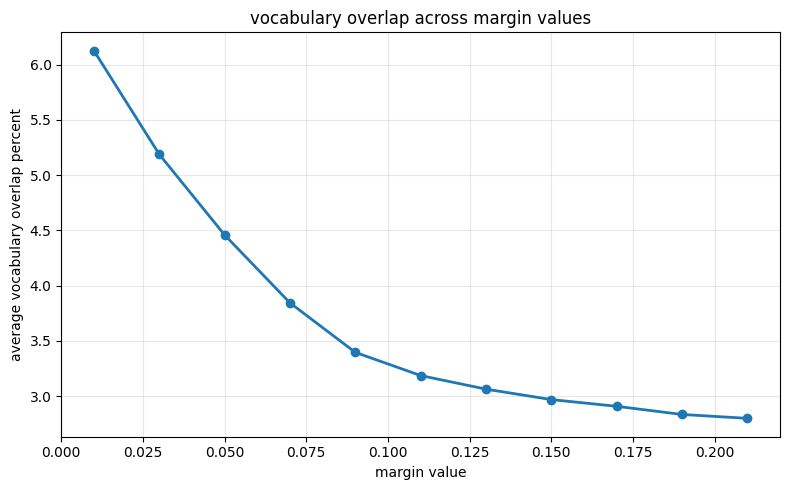

In [ ]:
import matplotlib.pyplot as plt

margins_list = [r[0] for r in results]
overlaps_list = [r[1] for r in results]

plt.figure(figsize=(8, 5))
plt.plot(margins_list, overlaps_list, marker='o', linewidth=2)
plt.xlabel('margin value')
plt.ylabel('average vocabulary overlap percent')
plt.title('vocabulary overlap across margin values')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('elbow_plot.png', dpi=150)
plt.show()

In [ ]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

tfidf_vec = TfidfVectorizer(max_features=20000, min_df=2, ngram_range=(1, 4))
tfidf_vec.fit(df_cascade['review_text'])

def get_tfidf_centroid(texts):
    vecs = tfidf_vec.transform(texts)
    return np.asarray(vecs.mean(axis=0))

ambiguity_margin = 0.2
max_passes = 10
frozen_pairs = set()

# phase 1 snapshot using evaluate_labeling so numbers match your table exactly
phase1_counts = df_cascade['review_rating'].value_counts().sort_index().to_dict()
phase1_means, phase1_overlaps, phase1_mono = evaluate_labeling(df_cascade, active_classes, 'phase 1 snapshot')
phase1_pairs = [(active_classes[i], active_classes[i+1]) for i in range(len(active_classes)-1)]
phase1_gaps = {(c1, c2): abs(phase1_means[c1]-phase1_means[c2]) for c1, c2 in phase1_pairs}
phase1_avg_gap = np.mean(list(phase1_gaps.values()))
phase1_avg_overlap = np.mean(list(phase1_overlaps.values()))

print_distribution(df_cascade, 'before phase 2, pure tfidf vocab cascade')

for pass_num in range(1, max_passes + 1):
    print(f'{"-"*60}')
    print(f'-- pass {pass_num} --------------------------------------------------')

    snapshot_means = {cls: df_cascade[df_cascade['review_rating'] == cls]['sentiment'].mean()
                       for cls in active_classes}

    active_pairs = [(a, b) for a, b in adjacent_pairs if (a, b) not in frozen_pairs]

    if not active_pairs:
        print('  all adjacent pairs frozen, stopping\n')
        break

    centroids = {cls: get_tfidf_centroid(df_cascade[df_cascade['review_rating'] == cls]['review_text'])
                 for cls in active_classes}

    ambiguous_records = {}
    for cls_a, cls_b in active_pairs:
        for cls_check in (cls_a, cls_b):
            mask_check = df_cascade['review_rating'] == cls_check
            idx_check = df_cascade[mask_check].index
            vecs_check = tfidf_vec.transform(df_cascade.loc[idx_check, 'review_text'])

            sim_to_a = cosine_similarity(vecs_check, centroids[cls_a]).flatten()
            sim_to_b = cosine_similarity(vecs_check, centroids[cls_b]).flatten()

            ambiguous_mask = np.abs(sim_to_a - sim_to_b) < ambiguity_margin
            for idx in idx_check[ambiguous_mask]:
                ambiguous_records.setdefault(idx, set()).update([cls_a, cls_b])

    print(f'  records in the shared ambiguous set this pass: {len(ambiguous_records)}')

    if not ambiguous_records:
        print('  no ambiguous records left, stopping\n')
        break

    ambiguous_idx_list = list(ambiguous_records.keys())
    texts = df_cascade.loc[ambiguous_idx_list, 'review_text']
    vecs = tfidf_vec.transform(texts)
    all_centroids = np.vstack([centroids[cls] for cls in active_classes])
    sims = cosine_similarity(vecs, all_centroids)

    reassignments = {}
    for row_i, idx in enumerate(ambiguous_idx_list):
        candidate_classes = ambiguous_records[idx]
        candidate_positions = [active_classes.index(c) for c in candidate_classes]
        candidate_sims = sims[row_i, candidate_positions]
        best_pos = candidate_positions[int(np.argmax(candidate_sims))]
        reassignments[idx] = active_classes[best_pos]

    changed = 0
    for idx, new_cls in reassignments.items():
        if df_cascade.loc[idx, 'review_rating'] != new_cls:
            changed += 1
        df_cascade.loc[idx, 'review_rating'] = new_cls

    print(f'  records reassigned to a different class this pass: {changed}')

    if changed == 0:
        print('  no reassignments changed anything, stopping\n')
        break

    new_means = {cls: df_cascade[df_cascade['review_rating'] == cls]['sentiment'].mean()
                 for cls in active_classes}

    newly_frozen = []
    for cls_a, cls_b in active_pairs:
        if new_means[cls_a] >= new_means[cls_b]:
            tmp = -cls_a
            df_cascade.loc[df_cascade['review_rating'] == cls_a, 'review_rating'] = tmp
            df_cascade.loc[df_cascade['review_rating'] == cls_b, 'review_rating'] = cls_a
            df_cascade.loc[df_cascade['review_rating'] == tmp, 'review_rating'] = cls_b
            new_means[cls_a], new_means[cls_b] = new_means[cls_b], new_means[cls_a]
            frozen_pairs.add((cls_a, cls_b))
            newly_frozen.append((cls_a, cls_b))

    if newly_frozen:
        print(f'  pairs frozen after this pass due to inversion (labels swapped to restore order): {newly_frozen}')
    print()

print_distribution(df_cascade, 'after phase 2, ordering-guarded tfidf vocab cascade')

# phase 2 snapshot using evaluate_labeling so overlap matches the printed per-pair values
phase2_counts = df_cascade['review_rating'].value_counts().sort_index().to_dict()
phase2_means, phase2_overlaps, phase2_mono = evaluate_labeling(df_cascade, active_classes, 'after phase 2, ordering-guarded tfidf vocab cascade')
phase2_pairs = [(active_classes[i], active_classes[i+1]) for i in range(len(active_classes)-1)]
phase2_gaps = {(c1, c2): abs(phase2_means[c1]-phase2_means[c2]) for c1, c2 in phase2_pairs}
phase2_avg_gap = np.mean(list(phase2_gaps.values()))
phase2_avg_overlap = np.mean(list(phase2_overlaps.values()))

df_temp_cascade = df_cascade.copy()

print('== comparison (phase 1 vs phase 2) ==================================')
print(f'{"Measure":40s}{"Phase 1":>28s}{"Phase 2":>28s}{"Change":>24s}')

for cls in active_classes:
    p1 = f'{phase1_counts[cls]:,} reviews (mean {phase1_means[cls]:+.3f})'
    p2 = f'{phase2_counts[cls]:,} reviews (mean {phase2_means[cls]:+.3f})'
    d = phase2_means[cls] - phase1_means[cls]
    direction = 'increased' if d > 0 else 'decreased'
    print(f'{"Rating " + str(cls):40s}{p1:>28s}{p2:>28s}{"Mean " + direction + f" by {abs(d):.3f}":>24s}')

for c1, c2 in phase2_pairs:
    g1 = phase1_gaps[(c1, c2)]
    g2 = phase2_gaps[(c1, c2)]
    d = g2 - g1
    direction = 'Improved' if d > 0 else 'Decreased'
    print(f'{f"Sentiment gap between ratings {c1} and {c2}":40s}{g1:>28.3f}{g2:>28.3f}{direction + f" by {abs(d):.3f}":>24s}')

d = phase2_avg_gap - phase1_avg_gap
direction = 'Improved' if d > 0 else 'Decreased'
print(f'{"Average adjacent sentiment gap":40s}{phase1_avg_gap:>28.3f}{phase2_avg_gap:>28.3f}{direction + f" by {abs(d):.3f}":>24s}')

for c1, c2 in phase2_pairs:
    o1 = phase1_overlaps[(c1, c2)]
    o2 = phase2_overlaps[(c1, c2)]
    d = o2 - o1
    direction = 'Decreased' if d < 0 else 'Increased'
    print(f'{f"Vocabulary overlap between ratings {c1} and {c2}":40s}{f"{o1:.1f}%":>28s}{f"{o2:.1f}%":>28s}{direction + f" by {abs(d):.1f}%":>24s}')

d = phase2_avg_overlap - phase1_avg_overlap
direction = 'Decreased' if d < 0 else 'Increased'
print(f'{"Average adjacent vocabulary overlap":40s}{f"{phase1_avg_overlap:.1f}%":>28s}{f"{phase2_avg_overlap:.1f}%":>28s}{direction + f" by {abs(d):.1f}%":>24s}')

print(f'{"Sentiment ordering":40s}{("Monotonic" if phase1_mono else "Not monotonic"):>28s}{("Monotonic" if phase2_mono else "Not monotonic"):>28s}{("Preserved" if phase1_mono and phase2_mono else "Changed"):>24s}')

-- phase 1 snapshot --------------------------------------------------
  cls1: sentiment mean -0.471  |  n 91860
  cls2: sentiment mean +0.061  |  n 108040
  cls3: sentiment mean +0.443  |  n 99624
  cls4: sentiment mean +0.624  |  n 100016
  cls5: sentiment mean +0.837  |  n 100595
  sentiment gaps (adjacent):  cls1->cls2: 0.532  cls2->cls3: 0.382  cls3->cls4: 0.181  cls4->cls5: 0.213  
  sentiment ordering: monotonic, valid
  vocab jaccard overlap (adjacent):  cls1vs2: 18.7%  cls2vs3: 17.9%  cls3vs4: 21.7%  cls4vs5: 20.2%  

-- before phase 2, pure tfidf vocab cascade --------------------------------------------------
review_rating
1     91860
2    108040
3     99624
4    100016
5    100595
Name: count, dtype: int64

------------------------------------------------------------
-- pass 1 --------------------------------------------------
  records in the shared ambiguous set this pass: 449661
  records reassigned to a different class this pass: 164823

--------------------------------

### **Phase 3: Sentiment Based Boundary Refinement (In Manuscript Section 4.2.3)**
First (first cell below) it find the opimtal value, and runs the same sentiment-midpoint refinement logic on a 10% sample copy (never touching df_temp_cascade itself), across a few candidate border_margin values with only a few passes each. It scores each candidate by the average sentiment gap between adjacent classes after refinement (higher gap = better separation) and only considers candidates that keep the class ordering monotonic, then prints the best one at the end. Once you see the result, set border_margin to that value manually before running the real refinement on the full dataset.

The (second one) code below is a third refinement pass, but based on raw sentiment score instead of TF-IDF similarity like phase 2. For each adjacent class pair, it finds the sentiment midpoint between the two classes and reassigns any record whose sentiment falls close to that midpoint (within border_margin) to whichever side it's actually closer to. It repeats this for a few passes so boundaries keep tightening, and if a pair's class means ever invert (lower class ends up with higher sentiment than the one above it), it swaps the labels back and freezes that pair so it's never touched again. At the end it compares the sentiment gap between each adjacent pair before and after, to show whether this pass sharpened or blurred the separation between classes.

In [ ]:
import numpy as np

sample_fraction = 0.20 # pertage of dataest
fine_passes_test = 3
border_margin_candidates = [0.01, 0.03, 0.05, 0.07, 0.09, 0.11, 0.13, 0.15, 0.17, 0.19, 0.21]

df_border_sample = df_temp_cascade.sample(frac=sample_fraction, random_state=42).copy()

def run_border_refinement(margin, df_in, passes):
    df_run = df_in.copy()
    frozen_pairs_local = set()

    for pass_num in range(passes):
        total_changed = 0
        active_pairs_local = [(a, b) for a, b in adjacent_pairs if (a, b) not in frozen_pairs_local]

        if not active_pairs_local:
            break

        for cls_a, cls_b in active_pairs_local:
            mean_a = df_run.loc[df_run['review_rating'] == cls_a, 'sentiment'].mean()
            mean_b = df_run.loc[df_run['review_rating'] == cls_b, 'sentiment'].mean()
            midpoint = (mean_a + mean_b) / 2

            mask_ab = df_run['review_rating'].isin([cls_a, cls_b])
            idx_ab = df_run.index[mask_ab]
            sentiments = df_run.loc[idx_ab, 'sentiment']

            borderline_mask = np.abs(sentiments - midpoint) < margin
            borderline_idx = idx_ab[borderline_mask]

            changed = 0
            for idx in borderline_idx:
                new_cls = cls_a if df_run.loc[idx, 'sentiment'] < midpoint else cls_b
                if df_run.loc[idx, 'review_rating'] != new_cls:
                    changed += 1
                    df_run.loc[idx, 'review_rating'] = new_cls
            total_changed += changed

            mean_a_check = df_run.loc[df_run['review_rating'] == cls_a, 'sentiment'].mean()
            mean_b_check = df_run.loc[df_run['review_rating'] == cls_b, 'sentiment'].mean()
            if mean_a_check >= mean_b_check:
                tmp = -cls_a
                df_run.loc[df_run['review_rating'] == cls_a, 'review_rating'] = tmp
                df_run.loc[df_run['review_rating'] == cls_b, 'review_rating'] = cls_a
                df_run.loc[df_run['review_rating'] == tmp, 'review_rating'] = cls_b
                frozen_pairs_local.add((cls_a, cls_b))

        if total_changed == 0:
            break

    return df_run

def score_border_result(df_in):
    means = {cls: df_in[df_in['review_rating'] == cls]['sentiment'].mean() for cls in active_classes}
    monotonic = all(means[adjacent_pairs[i][0]] < means[adjacent_pairs[i][1]] for i in range(len(adjacent_pairs)))

    gaps = [means[b] - means[a] for a, b in adjacent_pairs]
    avg_gap = np.mean(gaps)

    class_sizes = df_in['review_rating'].value_counts()
    min_class_size = class_sizes.min()

    return avg_gap, monotonic, min_class_size

results = []
for margin in border_margin_candidates:
    df_result = run_border_refinement(margin, df_border_sample, fine_passes_test)
    avg_gap, monotonic, min_class_size = score_border_result(df_result)
    results.append((margin, avg_gap, monotonic, min_class_size))
    print(f'margin {margin:.3f}: avg sentiment gap = {avg_gap:.3f}, monotonic = {monotonic}, smallest class n = {min_class_size}')

valid_results = [r for r in results if r[2]]
if valid_results:
    best_margin = max(valid_results, key=lambda r: r[1])[0]
    print(f'\nbest border_margin (highest avg gap, monotonic ordering held): {best_margin}')
else:
    print('\nno candidate kept monotonic ordering on this sample')

margin 0.010: avg sentiment gap = 0.217, monotonic = True, smallest class n = 7667
margin 0.030: avg sentiment gap = 0.218, monotonic = True, smallest class n = 7499
margin 0.050: avg sentiment gap = 0.220, monotonic = True, smallest class n = 7925
margin 0.070: avg sentiment gap = 0.221, monotonic = True, smallest class n = 7214
margin 0.090: avg sentiment gap = 0.226, monotonic = True, smallest class n = 7296
margin 0.110: avg sentiment gap = 0.228, monotonic = True, smallest class n = 7190
margin 0.130: avg sentiment gap = 0.247, monotonic = True, smallest class n = 12471
margin 0.150: avg sentiment gap = 0.252, monotonic = True, smallest class n = 13560
margin 0.170: avg sentiment gap = 0.256, monotonic = True, smallest class n = 13729
margin 0.190: avg sentiment gap = 0.258, monotonic = True, smallest class n = 14282
margin 0.210: avg sentiment gap = 0.260, monotonic = True, smallest class n = 15121

best border_margin (highest avg gap, monotonic ordering held): 0.21


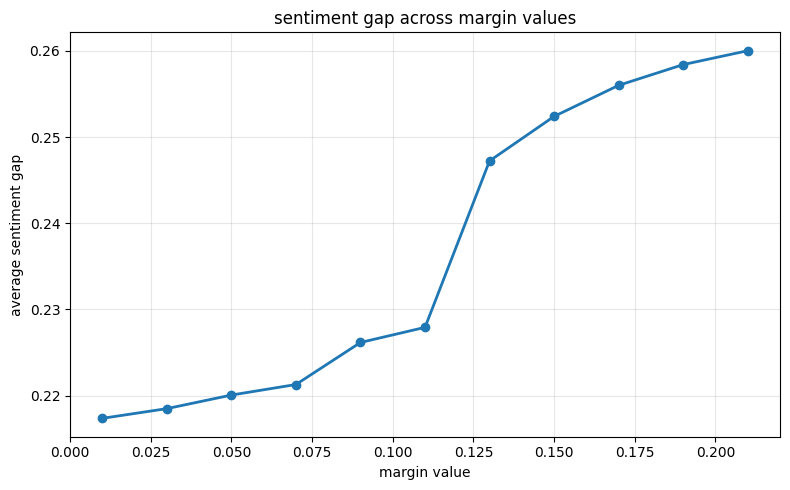

In [ ]:
import matplotlib.pyplot as plt

border_margins_list = [r[0] for r in results]
avg_gap_list = [r[1] for r in results]

plt.figure(figsize=(8, 5))
plt.plot(border_margins_list, avg_gap_list, marker='o', linewidth=2)
plt.xlabel('margin value')
plt.ylabel('average sentiment gap')
plt.title('sentiment gap across margin values')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('border_elbow_plot.png', dpi=150)
plt.show()

In [ ]:
import numpy as np

# ── sentiment-based boundary refinement across all adjacent pairs ──────────────

fine_passes   = 5
border_margin = 0.2

def adjacent_vocab_overlap(df_in):
    vocabs = {}
    for cls in active_classes:
        cls_content = df_in[df_in['review_rating'] == cls]['review_text'].fillna('').astype(str)
        vocabs[cls] = set(count_vec.build_analyzer()(' '.join(cls_content)))
    overlaps = {}
    for c1, c2 in adjacent_pairs:
        shared = len(vocabs[c1] & vocabs[c2])
        union = len(vocabs[c1] | vocabs[c2])
        overlaps[(c1, c2)] = shared / union * 100 if union else 0
    return overlaps

# snapshot before
print('-- sentiment-based refinement (all pairs): before --')
for cls in active_classes:
    mask = df_temp_cascade['review_rating'] == cls
    print(f'  cls{cls}: sentiment mean {df_temp_cascade.loc[mask, "sentiment"].mean():+.3f}  |  n {mask.sum()}')

gaps_before = {}
for cls_a, cls_b in adjacent_pairs:
    mean_a = df_temp_cascade.loc[df_temp_cascade['review_rating'] == cls_a, 'sentiment'].mean()
    mean_b = df_temp_cascade.loc[df_temp_cascade['review_rating'] == cls_b, 'sentiment'].mean()
    gaps_before[(cls_a, cls_b)] = mean_b - mean_a
    print(f'  gap cls{cls_a}->cls{cls_b}: {gaps_before[(cls_a, cls_b)]:+.3f}')

overlaps_before = adjacent_vocab_overlap(df_temp_cascade)
for cls_a, cls_b in adjacent_pairs:
    print(f'  vocab overlap cls{cls_a}vs{cls_b}: {overlaps_before[(cls_a, cls_b)]:.1f}%')
print(f'  avg vocab overlap: {np.mean(list(overlaps_before.values())):.1f}%')
print()

frozen_pairs_fine = set()

for pass_num in range(1, fine_passes + 1):
    print(f'  pass {pass_num}:')
    total_changed = 0

    active_pairs_fine = [(a, b) for a, b in adjacent_pairs if (a, b) not in frozen_pairs_fine]

    if not active_pairs_fine:
        print('    all pairs frozen, stopping\n')
        break

    for cls_a, cls_b in active_pairs_fine:
        mean_a   = df_temp_cascade.loc[df_temp_cascade['review_rating'] == cls_a, 'sentiment'].mean()
        mean_b   = df_temp_cascade.loc[df_temp_cascade['review_rating'] == cls_b, 'sentiment'].mean()
        midpoint = (mean_a + mean_b) / 2

        mask_ab    = df_temp_cascade['review_rating'].isin([cls_a, cls_b])
        idx_ab     = df_temp_cascade.index[mask_ab]
        sentiments = df_temp_cascade.loc[idx_ab, 'sentiment']

        borderline_mask = np.abs(sentiments - midpoint) < border_margin
        borderline_idx  = idx_ab[borderline_mask]

        changed = 0
        for idx in borderline_idx:
            new_cls = cls_a if df_temp_cascade.loc[idx, 'sentiment'] < midpoint else cls_b
            if df_temp_cascade.loc[idx, 'review_rating'] != new_cls:
                changed += 1
                df_temp_cascade.loc[idx, 'review_rating'] = new_cls

        total_changed += changed

        # guard: if ordering inverted swap back and freeze
        mean_a_check = df_temp_cascade.loc[df_temp_cascade['review_rating'] == cls_a, 'sentiment'].mean()
        mean_b_check = df_temp_cascade.loc[df_temp_cascade['review_rating'] == cls_b, 'sentiment'].mean()
        if mean_a_check >= mean_b_check:
            tmp = -cls_a
            df_temp_cascade.loc[df_temp_cascade['review_rating'] == cls_a, 'review_rating'] = tmp
            df_temp_cascade.loc[df_temp_cascade['review_rating'] == cls_b, 'review_rating'] = cls_a
            df_temp_cascade.loc[df_temp_cascade['review_rating'] == tmp,   'review_rating'] = cls_b
            frozen_pairs_fine.add((cls_a, cls_b))
            print(f'    cls{cls_a}/cls{cls_b}: inverted — swapped back and frozen')
        else:
            gap = mean_b_check - mean_a_check
            print(f'    cls{cls_a}/cls{cls_b}: moved {changed}  |  midpoint {midpoint:+.3f}  |  gap {gap:+.3f}')

    if total_changed == 0:
        print('  converged, stopping\n')
        break

# snapshot after
print()
print('-- sentiment-based refinement (all pairs): after --')
for cls in active_classes:
    mask = df_temp_cascade['review_rating'] == cls
    print(f'  cls{cls}: sentiment mean {df_temp_cascade.loc[mask, "sentiment"].mean():+.3f}  |  n {mask.sum()}')

print()
print('-- gap comparison --')
for cls_a, cls_b in adjacent_pairs:
    mean_a    = df_temp_cascade.loc[df_temp_cascade['review_rating'] == cls_a, 'sentiment'].mean()
    mean_b    = df_temp_cascade.loc[df_temp_cascade['review_rating'] == cls_b, 'sentiment'].mean()
    gap_after = mean_b - mean_a
    direction = 'improved' if gap_after > gaps_before[(cls_a, cls_b)] else 'narrowed'
    print(f'  cls{cls_a}->cls{cls_b}:  before {gaps_before[(cls_a, cls_b)]:+.3f}  |  after {gap_after:+.3f}  |  {direction}')

print()
print('-- vocab overlap comparison --')
overlaps_after = adjacent_vocab_overlap(df_temp_cascade)
for cls_a, cls_b in adjacent_pairs:
    ov_before = overlaps_before[(cls_a, cls_b)]
    ov_after  = overlaps_after[(cls_a, cls_b)]
    direction = 'improved' if ov_after < ov_before else 'weaker'
    print(f'  cls{cls_a}vs{cls_b}:  before {ov_before:.1f}%  |  after {ov_after:.1f}%  |  {direction}')
print(f'  avg vocab overlap:  before {np.mean(list(overlaps_before.values())):.1f}%  |  after {np.mean(list(overlaps_after.values())):.1f}%')

-- sentiment-based refinement (all pairs): before --
  cls1: sentiment mean -0.109  |  n 190889
  cls2: sentiment mean +0.114  |  n 56778
  cls3: sentiment mean +0.441  |  n 54062
  cls4: sentiment mean +0.660  |  n 73703
  cls5: sentiment mean +0.768  |  n 124703
  gap cls1->cls2: +0.223
  gap cls2->cls3: +0.328
  gap cls3->cls4: +0.219
  gap cls4->cls5: +0.108
  vocab overlap cls1vs2: 5.9%
  vocab overlap cls2vs3: 7.8%
  vocab overlap cls3vs4: 13.8%
  vocab overlap cls4vs5: 7.0%
  avg vocab overlap: 8.6%

  pass 1:
    cls1/cls2: moved 32356  |  midpoint +0.002  |  gap +0.273
    cls2/cls3: moved 20996  |  midpoint +0.301  |  gap +0.446
    cls3/cls4: moved 4205  |  midpoint +0.550  |  gap +0.232
    cls4/cls5: moved 55829  |  midpoint +0.716  |  gap +0.205
  pass 2:
    cls1/cls2: moved 78855  |  midpoint -0.059  |  gap +0.181
    cls2/cls3: moved 4313  |  midpoint +0.215  |  gap +0.436
    cls3/cls4: moved 734  |  midpoint +0.527  |  gap +0.209
    cls4/cls5: moved 6528  |  midpoin

In [ ]:
df_temp_cascade.info()

<class 'pandas.core.frame.DataFrame'>
Index: 500135 entries, 271919 to 121958
Data columns (total 11 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   app_id                  500135 non-null  object 
 1   app_name                500135 non-null  object 
 2   app_category            500135 non-null  object 
 3   app_aggregate_rating    500135 non-null  float64
 4   review_text             500135 non-null  object 
 5   review_rating           500135 non-null  int64  
 6   helpful_votes           500135 non-null  int64  
 7   review_date             500135 non-null  object 
 8   scraped_at              500135 non-null  object 
 9   review_rating_original  500135 non-null  int64  
 10  sentiment               500135 non-null  float64
dtypes: float64(2), int64(3), object(6)
memory usage: 61.9+ MB


In [ ]:
agreement_count = (
    df_temp_cascade["review_rating_original"]
    == df_temp_cascade["review_rating"]
).sum()

disagreement_count = len(df_temp_cascade) - agreement_count
disagreement_percentage = disagreement_count / len(df_temp_cascade) * 100

print(f"Agreement instances: {agreement_count:,}")
print(f"Disagreement instances: {disagreement_count:,}")
print(f"Disagreement percentage: {disagreement_percentage:.2f}%")

Agreement instances: 147,793
Disagreement instances: 352,342
Disagreement percentage: 70.45%


In [ ]:
rating_labels = [1, 2, 3, 4, 5]

for original_rating in rating_labels:
    original_reviews = df_temp_cascade[
        df_temp_cascade["review_rating_original"] == original_rating
    ]

    total_count = len(original_reviews)
    unchanged_count = (
        original_reviews["review_rating"] == original_rating
    ).sum()
    changed_count = total_count - unchanged_count
    changed_percentage = changed_count / total_count * 100

    print(f"\nOriginal rating {original_rating}:")
    print(f"Total instances: {total_count:,}")
    print(f"Unchanged instances: {unchanged_count:,}")
    print(f"Changed instances: {changed_count:,}")
    print(f"Changed percentage: {changed_percentage:.2f}%")

    for new_rating in rating_labels:
        if new_rating != original_rating:
            moved_count = (
                original_reviews["review_rating"] == new_rating
            ).sum()
            moved_percentage = moved_count / total_count * 100

            print(
                f"Moved from rating {original_rating} to rating "
                f"{new_rating}: {moved_count:,} "
                f"({moved_percentage:.2f}%)"
            )


Original rating 1:
Total instances: 117,997
Unchanged instances: 63,276
Changed instances: 54,721
Changed percentage: 46.37%
Moved from rating 1 to rating 2: 39,518 (33.49%)
Moved from rating 1 to rating 3: 2,500 (2.12%)
Moved from rating 1 to rating 4: 6,977 (5.91%)
Moved from rating 1 to rating 5: 5,726 (4.85%)

Original rating 2:
Total instances: 29,006
Unchanged instances: 7,970
Changed instances: 21,036
Changed percentage: 72.52%
Moved from rating 2 to rating 1: 14,655 (50.52%)
Moved from rating 2 to rating 3: 1,100 (3.79%)
Moved from rating 2 to rating 4: 2,658 (9.16%)
Moved from rating 2 to rating 5: 2,623 (9.04%)

Original rating 3:
Total instances: 31,407
Unchanged instances: 3,138
Changed instances: 28,269
Changed percentage: 90.01%
Moved from rating 3 to rating 1: 12,100 (38.53%)
Moved from rating 3 to rating 2: 7,926 (25.24%)
Moved from rating 3 to rating 4: 4,028 (12.83%)
Moved from rating 3 to rating 5: 4,215 (13.42%)

Original rating 4:
Total instances: 48,336
Unchanged

In [ ]:
# df_temp_cascade.to_csv('df_temp_cascade.csv', index=False)
# from google.colab import files
# files.download('df_temp_cascade.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### **Training the Classifier (In Manuscript Section 4.3)**

In [ ]:
import pandas as pd
main_df = pd.read_csv('/content/drive/MyDrive/Datasets/df_temp_cascade_multi_apps.csv') # combined_apps_reviews # gen_ai_reviews_main_dataset #gen_ai_reviews_5_apps_dataset #PlayStoreReviewsMultipleCategoires

main_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500135 entries, 0 to 500134
Data columns (total 10 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   app_id                500135 non-null  object 
 1   app_name              500135 non-null  object 
 2   app_category          500135 non-null  object 
 3   app_aggregate_rating  500135 non-null  float64
 4   review_text           500117 non-null  object 
 5   review_rating         500135 non-null  int64  
 6   helpful_votes         500135 non-null  int64  
 7   review_date           500135 non-null  object 
 8   scraped_at            500135 non-null  object 
 9   sentiment             500135 non-null  float64
dtypes: float64(2), int64(2), object(6)
memory usage: 38.2+ MB


In [ ]:
sample_percentage = 1 # Set the desired sample percentage (e.g., 0.50 for 50%, 1 for 100%)
df = main_df.sample(frac=sample_percentage, random_state=42) # random_state for reproducibility

print(f"New DataFrame size: {len(df)} records ({sample_percentage*100}% of original)")


New DataFrame size: 500135 records (100% of original)


In [ ]:
df = df[df['review_rating'].isin([1, 2, 3, 4, 5])]
len(df)

500135

### **The following classifier is trained and tested on the complete dataset (newly estimated sentiment labels), including all reviews across all categories and apps. The exact results and parameter settings are included in the manuscript.**

In [ ]:
import time
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report
from scipy.sparse import hstack, csr_matrix
import xgboost as xgb

start_time = time.time()

tfidf_xgb = TfidfVectorizer(max_features=20000, min_df=2, ngram_range=(1, 3))
X_tfidf = tfidf_xgb.fit_transform(df['review_text'].fillna(''))

numeric_cols = np.column_stack([
    df['sentiment'].fillna(0)
])

X_numeric = csr_matrix(numeric_cols)
X = hstack([X_tfidf, X_numeric])
y = df['review_rating'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

clf = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

label_map = {}
inv_label = {}
sorted_classes = sorted(df['review_rating'].unique())
for i, cls in enumerate(sorted_classes):
    label_map[cls] = i
    inv_label[i] = cls

y_train_enc = []
for v in y_train:
    y_train_enc.append(label_map[v])
y_train_enc = np.array(y_train_enc)

y_test_enc = []
for v in y_test:
    y_test_enc.append(label_map[v])
y_test_enc = np.array(y_test_enc)

clf.fit(X_train, y_train_enc)

y_pred_enc = clf.predict(X_test)

y_pred = []
for v in y_pred_enc:
    y_pred.append(inv_label[v])
y_pred = np.array(y_pred)

y_test_dec = []
for v in y_test_enc:
    y_test_dec.append(inv_label[v])
y_test_dec = np.array(y_test_dec)

acc = accuracy_score(y_test_dec, y_pred)
f1_mac = f1_score(y_test_dec, y_pred, average='macro')
f1_wt = f1_score(y_test_dec, y_pred, average='weighted')

class_labels = []
for c in sorted(label_map.keys()):
    class_labels.append(f'cls{c}')

print('xgboost classifier results')
print(f'  accuracy        : {acc:.4f}')
print(f'  f1 macro        : {f1_mac:.4f}')
print(f'  f1 weighted     : {f1_wt:.4f}')
print()
print(classification_report(y_test_dec, y_pred, target_names=class_labels))

elapsed = time.time() - start_time
minutes = int(elapsed // 60)
seconds = int(elapsed % 60)

print('execution time')
print(f'  total time      : {minutes:02d}:{seconds:02d}')
print()
print('dataset size')
print(f'  training records: {X_train.shape[0]}')
print(f'  testing records : {X_test.shape[0]}')
print()
print('parameter settings')
print('  vectorizer      : TfidfVectorizer(max_features=20000, min_df=2, ngram_range=(1, 3))')
print('  numeric features: sentiment')
print('  classifier      : XGBClassifier')
for param_name, param_value in clf.get_params().items():
    print(f'    {param_name} = {param_value}')

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [04:40:03] WARNING: /__w/xgboost/xgboost/src/learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


xgboost classifier results
  accuracy        : 0.9848
  f1 macro        : 0.9845
  f1 weighted     : 0.9848

              precision    recall  f1-score   support

        cls1       0.97      0.98      0.97     24059
        cls2       0.99      0.98      0.99     21008
        cls3       0.98      0.97      0.97     14821
        cls4       0.99      1.00      1.00     22860
        cls5       0.99      0.99      0.99     17279

    accuracy                           0.98    100027
   macro avg       0.99      0.98      0.98    100027
weighted avg       0.98      0.98      0.98    100027

execution time
  total time      : 46:00

dataset size
  training records: 400108
  testing records : 100027

parameter settings
  vectorizer      : TfidfVectorizer(max_features=20000, min_df=2, ngram_range=(1, 3))
  numeric features: sentiment
  classifier      : XGBClassifier
    objective = multi:softprob
    base_score = None
    booster = None
    callbacks = None
    colsample_bylevel = None
 

In [ ]:
df['app_category'].value_counts()

,count
app_category,
entertainment,100187
education,100023
ai,100003
music,100000
health and fitness,99922


### **The following classifier is trained and tested separately on each of the five app categories. These results are not included in the manuscript.**

In [ ]:
df_entertainment = df[df['app_category'] == 'entertainment']
df_education = df[df['app_category'] == 'education']
df_ai = df[df['app_category'] == 'ai']
df_music  = df[df['app_category'] == 'music']
df_health_fitness = df[df['app_category'] == 'health and fitness']

In [ ]:
import time
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report
from scipy.sparse import hstack, csr_matrix
import xgboost as xgb

df_sub = df_entertainment

start_time = time.time()

tfidf_xgb = TfidfVectorizer(
    max_features=20000,
    min_df=2,
    ngram_range=(1, 3)
)

X_tfidf = tfidf_xgb.fit_transform(
    df_sub['review_text'].fillna('')
)

numeric_cols = np.column_stack([
    df_sub['sentiment'].fillna(0)
])

X_numeric = csr_matrix(numeric_cols)
X = hstack([X_tfidf, X_numeric])
y = df_sub['review_rating'].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

clf = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

label_map = {}
inv_label = {}
sorted_classes = sorted(df_sub['review_rating'].unique())

for i, cls in enumerate(sorted_classes):
    label_map[cls] = i
    inv_label[i] = cls

y_train_enc = []

for v in y_train:
    y_train_enc.append(label_map[v])

y_train_enc = np.array(y_train_enc)

y_test_enc = []

for v in y_test:
    y_test_enc.append(label_map[v])

y_test_enc = np.array(y_test_enc)

clf.fit(X_train, y_train_enc)

y_pred_enc = clf.predict(X_test)

y_pred = []

for v in y_pred_enc:
    y_pred.append(inv_label[v])

y_pred = np.array(y_pred)

y_test_dec = []

for v in y_test_enc:
    y_test_dec.append(inv_label[v])

y_test_dec = np.array(y_test_dec)

acc = accuracy_score(y_test_dec, y_pred)
f1_mac = f1_score(y_test_dec, y_pred, average='macro')
f1_wt = f1_score(y_test_dec, y_pred, average='weighted')

class_labels = []

for c in sorted(label_map.keys()):
    class_labels.append(f'cls{c}')

print('xgboost classifier results')
print(f'  accuracy        : {acc:.4f}')
print(f'  f1 macro        : {f1_mac:.4f}')
print(f'  f1 weighted     : {f1_wt:.4f}')
print()
print(
    classification_report(
        y_test_dec,
        y_pred,
        target_names=class_labels
    )
)

elapsed = time.time() - start_time
minutes = int(elapsed // 60)
seconds = int(elapsed % 60)

print('execution time')
print(f'  total time      : {minutes:02d}:{seconds:02d}')
print()
print('dataset size')
print(f'  training records: {X_train.shape[0]}')
print(f'  testing records : {X_test.shape[0]}')
print()
print('parameter settings')
print(
    '  vectorizer      : '
    'TfidfVectorizer(max_features=20000, min_df=2, '
    'ngram_range=(1, 3))'
)
print('  numeric features: sentiment')
print('  classifier      : XGBClassifier')

for param_name, param_value in clf.get_params().items():
    print(f'    {param_name} = {param_value}')


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [07:24:11] WARNING: /__w/xgboost/xgboost/src/learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


xgboost classifier results
  accuracy        : 0.9832
  f1 macro        : 0.9816
  f1 weighted     : 0.9832

              precision    recall  f1-score   support

        cls1       0.97      0.98      0.98      5523
        cls2       0.99      0.98      0.99      5114
        cls3       0.97      0.96      0.96      2061
        cls4       0.99      0.99      0.99      4388
        cls5       0.99      0.99      0.99      2952

    accuracy                           0.98     20038
   macro avg       0.98      0.98      0.98     20038
weighted avg       0.98      0.98      0.98     20038

execution time
  total time      : 11:31

dataset size
  training records: 80149
  testing records : 20038

parameter settings
  vectorizer      : TfidfVectorizer(max_features=20000, min_df=2, ngram_range=(1, 3))
  numeric features: sentiment
  classifier      : XGBClassifier
    objective = multi:softprob
    base_score = None
    booster = None
    callbacks = None
    colsample_bylevel = None
   

In [ ]:
import time
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report
from scipy.sparse import hstack, csr_matrix
import xgboost as xgb

df_sub = df_education

start_time = time.time()

tfidf_xgb = TfidfVectorizer(
    max_features=20000,
    min_df=2,
    ngram_range=(1, 3)
)

X_tfidf = tfidf_xgb.fit_transform(
    df_sub['review_text'].fillna('')
)

numeric_cols = np.column_stack([
    df_sub['sentiment'].fillna(0)
])

X_numeric = csr_matrix(numeric_cols)
X = hstack([X_tfidf, X_numeric])
y = df_sub['review_rating'].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

clf = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

label_map = {}
inv_label = {}
sorted_classes = sorted(df_sub['review_rating'].unique())

for i, cls in enumerate(sorted_classes):
    label_map[cls] = i
    inv_label[i] = cls

y_train_enc = []

for v in y_train:
    y_train_enc.append(label_map[v])

y_train_enc = np.array(y_train_enc)

y_test_enc = []

for v in y_test:
    y_test_enc.append(label_map[v])

y_test_enc = np.array(y_test_enc)

clf.fit(X_train, y_train_enc)

y_pred_enc = clf.predict(X_test)

y_pred = []

for v in y_pred_enc:
    y_pred.append(inv_label[v])

y_pred = np.array(y_pred)

y_test_dec = []

for v in y_test_enc:
    y_test_dec.append(inv_label[v])

y_test_dec = np.array(y_test_dec)

acc = accuracy_score(y_test_dec, y_pred)
f1_mac = f1_score(y_test_dec, y_pred, average='macro')
f1_wt = f1_score(y_test_dec, y_pred, average='weighted')

class_labels = []

for c in sorted(label_map.keys()):
    class_labels.append(f'cls{c}')

print('xgboost classifier results')
print(f'  accuracy        : {acc:.4f}')
print(f'  f1 macro        : {f1_mac:.4f}')
print(f'  f1 weighted     : {f1_wt:.4f}')
print()
print(
    classification_report(
        y_test_dec,
        y_pred,
        target_names=class_labels
    )
)

elapsed = time.time() - start_time
minutes = int(elapsed // 60)
seconds = int(elapsed % 60)

print('execution time')
print(f'  total time      : {minutes:02d}:{seconds:02d}')
print()
print('dataset size')
print(f'  training records: {X_train.shape[0]}')
print(f'  testing records : {X_test.shape[0]}')
print()
print('parameter settings')
print(
    '  vectorizer      : '
    'TfidfVectorizer(max_features=20000, min_df=2, '
    'ngram_range=(1, 3))'
)
print('  numeric features: sentiment')
print('  classifier      : XGBClassifier')

for param_name, param_value in clf.get_params().items():
    print(f'    {param_name} = {param_value}')


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [07:36:01] WARNING: /__w/xgboost/xgboost/src/learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


xgboost classifier results
  accuracy        : 0.9814
  f1 macro        : 0.9790
  f1 weighted     : 0.9814

              precision    recall  f1-score   support

        cls1       0.95      0.96      0.96      3338
        cls2       0.99      0.97      0.98      3415
        cls3       0.97      0.97      0.97      3418
        cls4       0.99      1.00      1.00      5385
        cls5       0.99      0.99      0.99      4449

    accuracy                           0.98     20005
   macro avg       0.98      0.98      0.98     20005
weighted avg       0.98      0.98      0.98     20005

execution time
  total time      : 11:15

dataset size
  training records: 80018
  testing records : 20005

parameter settings
  vectorizer      : TfidfVectorizer(max_features=20000, min_df=2, ngram_range=(1, 3))
  numeric features: sentiment
  classifier      : XGBClassifier
    objective = multi:softprob
    base_score = None
    booster = None
    callbacks = None
    colsample_bylevel = None
   

In [ ]:
import time
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report
from scipy.sparse import hstack, csr_matrix
import xgboost as xgb

df_sub = df_ai

start_time = time.time()

tfidf_xgb = TfidfVectorizer(
    max_features=20000,
    min_df=2,
    ngram_range=(1, 3)
)

X_tfidf = tfidf_xgb.fit_transform(
    df_sub['review_text'].fillna('')
)

numeric_cols = np.column_stack([
    df_sub['sentiment'].fillna(0)
])

X_numeric = csr_matrix(numeric_cols)
X = hstack([X_tfidf, X_numeric])
y = df_sub['review_rating'].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

clf = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

label_map = {}
inv_label = {}
sorted_classes = sorted(df_sub['review_rating'].unique())

for i, cls in enumerate(sorted_classes):
    label_map[cls] = i
    inv_label[i] = cls

y_train_enc = []

for v in y_train:
    y_train_enc.append(label_map[v])

y_train_enc = np.array(y_train_enc)

y_test_enc = []

for v in y_test:
    y_test_enc.append(label_map[v])

y_test_enc = np.array(y_test_enc)

clf.fit(X_train, y_train_enc)

y_pred_enc = clf.predict(X_test)

y_pred = []

for v in y_pred_enc:
    y_pred.append(inv_label[v])

y_pred = np.array(y_pred)

y_test_dec = []

for v in y_test_enc:
    y_test_dec.append(inv_label[v])

y_test_dec = np.array(y_test_dec)

acc = accuracy_score(y_test_dec, y_pred)
f1_mac = f1_score(y_test_dec, y_pred, average='macro')
f1_wt = f1_score(y_test_dec, y_pred, average='weighted')

class_labels = []

for c in sorted(label_map.keys()):
    class_labels.append(f'cls{c}')

print('xgboost classifier results')
print(f'  accuracy        : {acc:.4f}')
print(f'  f1 macro        : {f1_mac:.4f}')
print(f'  f1 weighted     : {f1_wt:.4f}')
print()
print(
    classification_report(
        y_test_dec,
        y_pred,
        target_names=class_labels
    )
)

elapsed = time.time() - start_time
minutes = int(elapsed // 60)
seconds = int(elapsed % 60)

print('execution time')
print(f'  total time      : {minutes:02d}:{seconds:02d}')
print()
print('dataset size')
print(f'  training records: {X_train.shape[0]}')
print(f'  testing records : {X_test.shape[0]}')
print()
print('parameter settings')
print(
    '  vectorizer      : '
    'TfidfVectorizer(max_features=20000, min_df=2, '
    'ngram_range=(1, 3))'
)
print('  numeric features: sentiment')
print('  classifier      : XGBClassifier')

for param_name, param_value in clf.get_params().items():
    print(f'    {param_name} = {param_value}')


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [07:47:17] WARNING: /__w/xgboost/xgboost/src/learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


xgboost classifier results
  accuracy        : 0.9798
  f1 macro        : 0.9805
  f1 weighted     : 0.9798

              precision    recall  f1-score   support

        cls1       0.96      0.98      0.97      5101
        cls2       0.99      0.97      0.98      4311
        cls3       0.97      0.97      0.97      3525
        cls4       0.99      1.00      0.99      4194
        cls5       0.99      0.99      0.99      2870

    accuracy                           0.98     20001
   macro avg       0.98      0.98      0.98     20001
weighted avg       0.98      0.98      0.98     20001

execution time
  total time      : 12:08

dataset size
  training records: 80002
  testing records : 20001

parameter settings
  vectorizer      : TfidfVectorizer(max_features=20000, min_df=2, ngram_range=(1, 3))
  numeric features: sentiment
  classifier      : XGBClassifier
    objective = multi:softprob
    base_score = None
    booster = None
    callbacks = None
    colsample_bylevel = None
   

In [ ]:
import time
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report
from scipy.sparse import hstack, csr_matrix
import xgboost as xgb

df_sub = df_music

start_time = time.time()

tfidf_xgb = TfidfVectorizer(
    max_features=20000,
    min_df=2,
    ngram_range=(1, 3)
)

X_tfidf = tfidf_xgb.fit_transform(
    df_sub['review_text'].fillna('')
)

numeric_cols = np.column_stack([
    df_sub['sentiment'].fillna(0)
])

X_numeric = csr_matrix(numeric_cols)
X = hstack([X_tfidf, X_numeric])
y = df_sub['review_rating'].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

clf = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

label_map = {}
inv_label = {}
sorted_classes = sorted(df_sub['review_rating'].unique())

for i, cls in enumerate(sorted_classes):
    label_map[cls] = i
    inv_label[i] = cls

y_train_enc = []

for v in y_train:
    y_train_enc.append(label_map[v])

y_train_enc = np.array(y_train_enc)

y_test_enc = []

for v in y_test:
    y_test_enc.append(label_map[v])

y_test_enc = np.array(y_test_enc)

clf.fit(X_train, y_train_enc)

y_pred_enc = clf.predict(X_test)

y_pred = []

for v in y_pred_enc:
    y_pred.append(inv_label[v])

y_pred = np.array(y_pred)

y_test_dec = []

for v in y_test_enc:
    y_test_dec.append(inv_label[v])

y_test_dec = np.array(y_test_dec)

acc = accuracy_score(y_test_dec, y_pred)
f1_mac = f1_score(y_test_dec, y_pred, average='macro')
f1_wt = f1_score(y_test_dec, y_pred, average='weighted')

class_labels = []

for c in sorted(label_map.keys()):
    class_labels.append(f'cls{c}')

print('xgboost classifier results')
print(f'  accuracy        : {acc:.4f}')
print(f'  f1 macro        : {f1_mac:.4f}')
print(f'  f1 weighted     : {f1_wt:.4f}')
print()
print(
    classification_report(
        y_test_dec,
        y_pred,
        target_names=class_labels
    )
)

elapsed = time.time() - start_time
minutes = int(elapsed // 60)
seconds = int(elapsed % 60)

print('execution time')
print(f'  total time      : {minutes:02d}:{seconds:02d}')
print()
print('dataset size')
print(f'  training records: {X_train.shape[0]}')
print(f'  testing records : {X_test.shape[0]}')
print()
print('parameter settings')
print(
    '  vectorizer      : '
    'TfidfVectorizer(max_features=20000, min_df=2, '
    'ngram_range=(1, 3))'
)
print('  numeric features: sentiment')
print('  classifier      : XGBClassifier')

for param_name, param_value in clf.get_params().items():
    print(f'    {param_name} = {param_value}')

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [07:10:03] WARNING: /__w/xgboost/xgboost/src/learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


xgboost classifier results
  accuracy        : 0.9825
  f1 macro        : 0.9823
  f1 weighted     : 0.9825

              precision    recall  f1-score   support

        cls1       0.96      0.98      0.97      4998
        cls2       0.99      0.98      0.98      4545
        cls3       0.98      0.97      0.97      3229
        cls4       0.99      1.00      0.99      4866
        cls5       0.98      0.99      0.99      2362

    accuracy                           0.98     20000
   macro avg       0.98      0.98      0.98     20000
weighted avg       0.98      0.98      0.98     20000

execution time
  total time      : 10:51

dataset size
  training records: 80000
  testing records : 20000

parameter settings
  vectorizer      : TfidfVectorizer(max_features=20000, min_df=2, ngram_range=(1, 3))
  numeric features: sentiment
  classifier      : XGBClassifier
    objective = multi:softprob
    base_score = None
    booster = None
    callbacks = None
    colsample_bylevel = None
   

In [ ]:
import time
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report
from scipy.sparse import hstack, csr_matrix
import xgboost as xgb

df_sub = df_health_fitness

start_time = time.time()

tfidf_xgb = TfidfVectorizer(
    max_features=20000,
    min_df=2,
    ngram_range=(1, 3)
)

X_tfidf = tfidf_xgb.fit_transform(
    df_sub['review_text'].fillna('')
)

numeric_cols = np.column_stack([
    df_sub['sentiment'].fillna(0)
])

X_numeric = csr_matrix(numeric_cols)
X = hstack([X_tfidf, X_numeric])
y = df_sub['review_rating'].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

clf = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

label_map = {}
inv_label = {}
sorted_classes = sorted(df_sub['review_rating'].unique())

for i, cls in enumerate(sorted_classes):
    label_map[cls] = i
    inv_label[i] = cls

y_train_enc = []

for v in y_train:
    y_train_enc.append(label_map[v])

y_train_enc = np.array(y_train_enc)

y_test_enc = []

for v in y_test:
    y_test_enc.append(label_map[v])

y_test_enc = np.array(y_test_enc)

clf.fit(X_train, y_train_enc)

y_pred_enc = clf.predict(X_test)

y_pred = []

for v in y_pred_enc:
    y_pred.append(inv_label[v])

y_pred = np.array(y_pred)

y_test_dec = []

for v in y_test_enc:
    y_test_dec.append(inv_label[v])

y_test_dec = np.array(y_test_dec)

acc = accuracy_score(y_test_dec, y_pred)
f1_mac = f1_score(y_test_dec, y_pred, average='macro')
f1_wt = f1_score(y_test_dec, y_pred, average='weighted')

class_labels = []

for c in sorted(label_map.keys()):
    class_labels.append(f'cls{c}')

print('xgboost classifier results')
print(f'  accuracy        : {acc:.4f}')
print(f'  f1 macro        : {f1_mac:.4f}')
print(f'  f1 weighted     : {f1_wt:.4f}')
print()
print(
    classification_report(
        y_test_dec,
        y_pred,
        target_names=class_labels
    )
)

elapsed = time.time() - start_time
minutes = int(elapsed // 60)
seconds = int(elapsed % 60)

print('execution time')
print(f'  total time      : {minutes:02d}:{seconds:02d}')
print()
print('dataset size')
print(f'  training records: {X_train.shape[0]}')
print(f'  testing records : {X_test.shape[0]}')
print()
print('parameter settings')
print(
    '  vectorizer      : '
    'TfidfVectorizer(max_features=20000, min_df=2, '
    'ngram_range=(1, 3))'
)
print('  numeric features: sentiment')
print('  classifier      : XGBClassifier')

for param_name, param_value in clf.get_params().items():
    print(f'    {param_name} = {param_value}')


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [07:59:30] WARNING: /__w/xgboost/xgboost/src/learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


xgboost classifier results
  accuracy        : 0.9842
  f1 macro        : 0.9830
  f1 weighted     : 0.9842

              precision    recall  f1-score   support

        cls1       0.97      0.98      0.98      5100
        cls2       0.99      0.98      0.99      3624
        cls3       0.97      0.96      0.96      2588
        cls4       1.00      0.99      1.00      4027
        cls5       0.99      0.99      0.99      4646

    accuracy                           0.98     19985
   macro avg       0.98      0.98      0.98     19985
weighted avg       0.98      0.98      0.98     19985

execution time
  total time      : 14:26

dataset size
  training records: 79937
  testing records : 19985

parameter settings
  vectorizer      : TfidfVectorizer(max_features=20000, min_df=2, ngram_range=(1, 3))
  numeric features: sentiment
  classifier      : XGBClassifier
    objective = multi:softprob
    base_score = None
    booster = None
    callbacks = None
    colsample_bylevel = None
   

### **The following classifier is trained and tested on the raw star rating labels across the complete dataset, including all reviews from every category and app. The exact results and parameter settings are included in the manuscript.**

In [ ]:
import pandas as pd
main_df = pd.read_csv('/content/drive/MyDrive/Datasets/PlayStoreReviewsMultipleCategoires.csv') # combined_apps_reviews # gen_ai_reviews_main_dataset #gen_ai_reviews_5_apps_dataset #PlayStoreReviewsMultipleCategoires

main_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500135 entries, 0 to 500134
Data columns (total 9 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   app_id                500135 non-null  object 
 1   app_name              500135 non-null  object 
 2   app_category          500135 non-null  object 
 3   app_aggregate_rating  500135 non-null  float64
 4   review_text           500117 non-null  object 
 5   review_rating         500135 non-null  int64  
 6   helpful_votes         500135 non-null  int64  
 7   review_date           500135 non-null  object 
 8   scraped_at            500135 non-null  object 
dtypes: float64(1), int64(2), object(6)
memory usage: 34.3+ MB


In [ ]:
sample_percentage = 1 # Set the desired sample percentage (e.g., 0.50 for 50%, 1 for 100%)
df = main_df.sample(frac=sample_percentage, random_state=42) # random_state for reproducibility

print(f"New DataFrame size: {len(df)} records ({sample_percentage*100}% of original)")


New DataFrame size: 500135 records (100% of original)


In [ ]:
df = df[df['review_rating'].isin([1, 2, 3, 4, 5])]
len(df)

500135

In [ ]:
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk.download('vader_lexicon')

sentiment_analyzer = SentimentIntensityAnalyzer()

df['sentiment'] = df['review_text'].fillna('').astype(str).apply(
    lambda text: sentiment_analyzer.polarity_scores(text)['compound']
)

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


In [ ]:
import time
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report
from scipy.sparse import hstack, csr_matrix
import xgboost as xgb

start_time = time.time()

tfidf_xgb = TfidfVectorizer(max_features=20000, min_df=2, ngram_range=(1, 3))
X_tfidf = tfidf_xgb.fit_transform(df['review_text'].fillna(''))

numeric_cols = np.column_stack([
    df['sentiment'].fillna(0)
])

X_numeric = csr_matrix(numeric_cols)
X = hstack([X_tfidf, X_numeric])
y = df['review_rating'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

clf = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

label_map = {}
inv_label = {}
sorted_classes = sorted(df['review_rating'].unique())
for i, cls in enumerate(sorted_classes):
    label_map[cls] = i
    inv_label[i] = cls

y_train_enc = []
for v in y_train:
    y_train_enc.append(label_map[v])
y_train_enc = np.array(y_train_enc)

y_test_enc = []
for v in y_test:
    y_test_enc.append(label_map[v])
y_test_enc = np.array(y_test_enc)

clf.fit(X_train, y_train_enc)

y_pred_enc = clf.predict(X_test)

y_pred = []
for v in y_pred_enc:
    y_pred.append(inv_label[v])
y_pred = np.array(y_pred)

y_test_dec = []
for v in y_test_enc:
    y_test_dec.append(inv_label[v])
y_test_dec = np.array(y_test_dec)

acc = accuracy_score(y_test_dec, y_pred)
f1_mac = f1_score(y_test_dec, y_pred, average='macro')
f1_wt = f1_score(y_test_dec, y_pred, average='weighted')

class_labels = []
for c in sorted(label_map.keys()):
    class_labels.append(f'cls{c}')

print('xgboost classifier results')
print(f'  accuracy        : {acc:.4f}')
print(f'  f1 macro        : {f1_mac:.4f}')
print(f'  f1 weighted     : {f1_wt:.4f}')
print()
print(classification_report(y_test_dec, y_pred, target_names=class_labels))

elapsed = time.time() - start_time
minutes = int(elapsed // 60)
seconds = int(elapsed % 60)

print('execution time')
print(f'  total time      : {minutes:02d}:{seconds:02d}')
print()
print('dataset size')
print(f'  training records: {X_train.shape[0]}')
print(f'  testing records : {X_test.shape[0]}')
print()
print('parameter settings')
print('  vectorizer      : TfidfVectorizer(max_features=20000, min_df=2, ngram_range=(1, 3))')
print('  numeric features: sentiment')
print('  classifier      : XGBClassifier')
for param_name, param_value in clf.get_params().items():
    print(f'    {param_name} = {param_value}')

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [05:34:42] WARNING: /__w/xgboost/xgboost/src/learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


xgboost classifier results
  accuracy        : 0.7335
  f1 macro        : 0.3988
  f1 weighted     : 0.6774

              precision    recall  f1-score   support

        cls1       0.66      0.83      0.74     23599
        cls2       0.31      0.03      0.05      5801
        cls3       0.36      0.08      0.13      6282
        cls4       0.41      0.14      0.21      9667
        cls5       0.79      0.95      0.86     54678

    accuracy                           0.73    100027
   macro avg       0.51      0.41      0.40    100027
weighted avg       0.67      0.73      0.68    100027

execution time
  total time      : 68:45

dataset size
  training records: 400108
  testing records : 100027

parameter settings
  vectorizer      : TfidfVectorizer(max_features=20000, min_df=2, ngram_range=(1, 3))
  numeric features: sentiment
  classifier      : XGBClassifier
    objective = multi:softprob
    base_score = None
    booster = None
    callbacks = None
    colsample_bylevel = None
 